# Trois mini-projets réels d’évaluation en vision

**Classification → détection → segmentation sémantique et d’instances.**

Toutes les images, annotations et prédictions utilisées ici sont réelles. Les chiffres viennent d’UCI via scikit-learn ; les piétons de Penn-Fudan. Les scores sont calculés à l’exécution. Les sorties enregistrées décrivent uniquement le protocole indiqué ci-dessous.

Installer `requirements-dev.txt` avec Python 3.11/3.12 (voir README), puis redémarrer le noyau et **Exécuter tout**. Premier lancement : téléchargement de Penn-Fudan et des deux modèles (~380 Mio au total, hors bibliothèques). Les exécutions suivantes utilisent le cache local. Aucun GPU nécessaire.

In [1]:
from pathlib import Path
import json
import os
import sys
from IPython.display import Image, display

# Le notebook fonctionne depuis la racine du dépôt ou son dossier notebooks.
RACINE = Path.cwd().resolve()
if not (RACINE / "run_all.py").exists():
    RACINE = RACINE.parent
assert (RACINE / "run_all.py").exists(), "Ouvrir le notebook depuis le dépôt."
sys.path.insert(0, str(RACINE))
LIMITE = 20       # 0 pour toutes les 170 images Penn-Fudan
GRAINE = 42
SEUIL = 0.5       # confiance pour les figures et la sémantique, pas pour l'AP
DONNEES = Path(os.environ.get("CV_DONNEES", str(RACINE / "data")))
SORTIE = Path(os.environ.get("CV_SORTIE", str(RACINE / "resultats")))

from examples.commun import sauver_json
from examples.classification_metrics import executer as classer
from examples.pietons import executer as evaluer_pietons

def afficher_resume(objet):
    print(json.dumps(objet, indent=2, ensure_ascii=False))


## 1 — Lire des chiffres manuscrits

**Question concrète :** reconnaître le chiffre écrit, puis déterminer s’il est pair.

1 797 images 8 × 8 issues de vrais manuscrits. Découpage stratifié 75/25, graine 42. Les 450 images de test ne sont utilisées ni pour ajuster le scaler ni pour entraîner les régressions logistiques. Les hyperparamètres sont fixés avant l’évaluation.

Le code complet de l’apprentissage est dans `examples/classification_metrics.py` : `load_digits` → `train_test_split` → `Pipeline(StandardScaler, LogisticRegression)` → `fit` sur apprentissage → `predict` sur test. Un second modèle est entraîné sur la parité des étiquettes réelles. Cette partition est interne au sous-ensemble scikit-learn ; elle ne reproduit pas le test officiel UCI ni une séparation par scripteur.

Classification : 450 images de test ; accuracy=0.9778


{
  "images_apprentissage": 1347,
  "images_test": 450,
  "accuracy": 0.9777777777777777,
  "f1_macro": 0.9776411985388958,
  "pair_impair": {
    "classe_positive": "chiffre pair",
    "seuil": 0.5,
    "accuracy": 0.9133333333333333,
    "precision": 0.9178082191780822,
    "rappel": 0.9054054054054054,
    "f1": 0.9115646258503401,
    "roc_auc": 0.9704638849375692,
    "average_precision": 0.9607099963203849,
    "matrice_confusion": [
      [
        210,
        18
      ],
      [
        21,
        201
      ]
    ]
  }
}


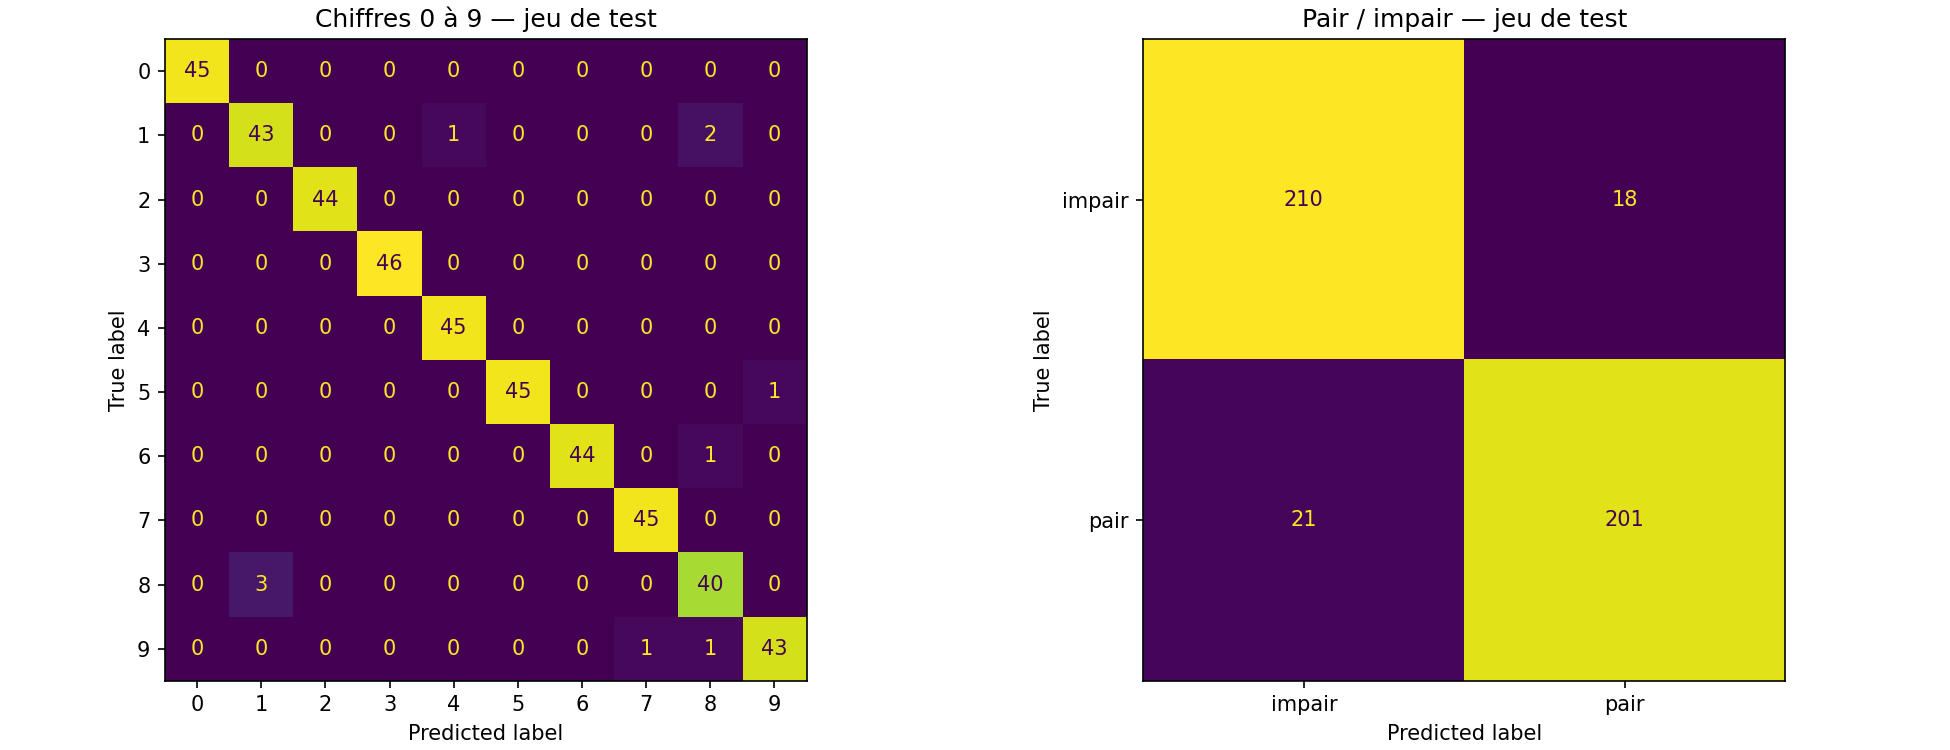

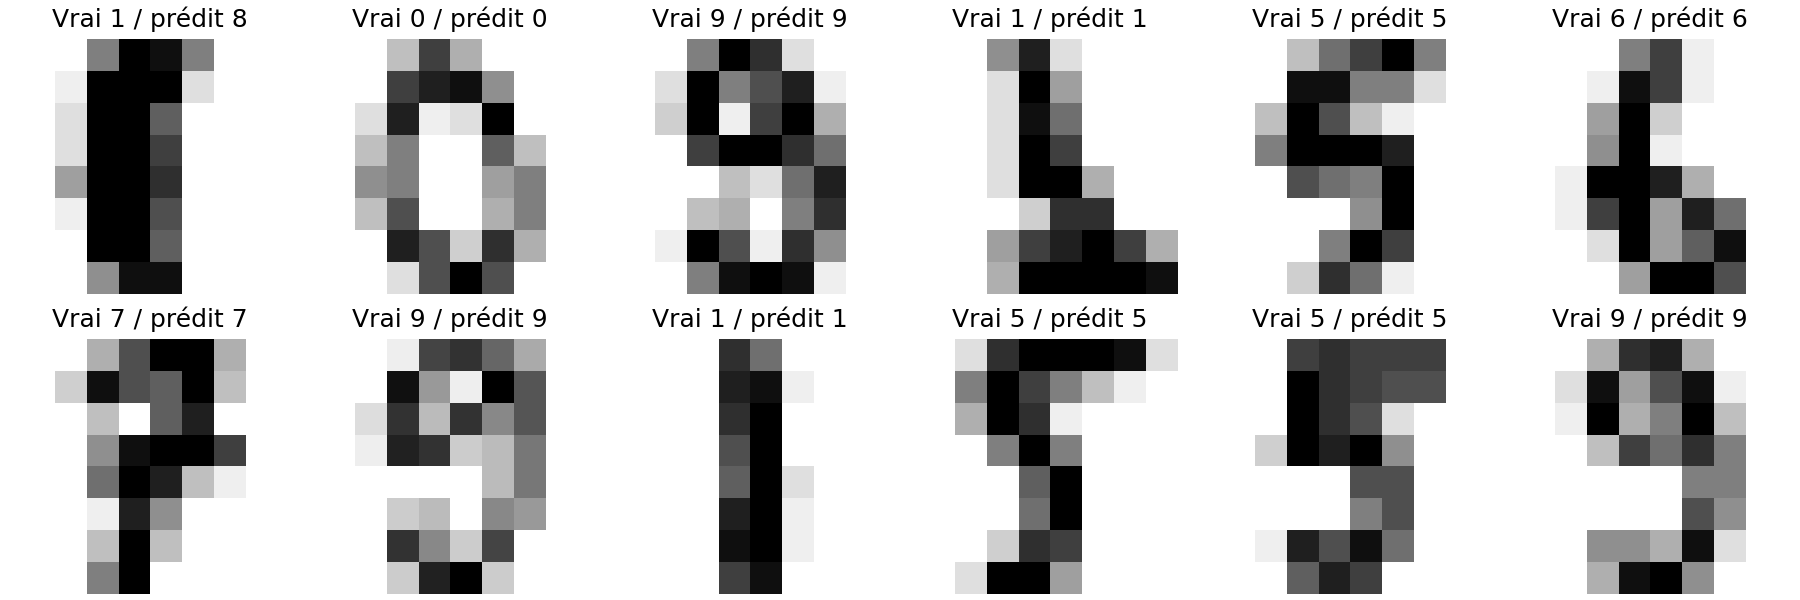

In [2]:
classification = classer(sortie=SORTIE, graine=GRAINE)
afficher_resume({
    "images_apprentissage": classification["n_apprentissage"],
    "images_test": classification["n_test"],
    "accuracy": classification["multiclasse"]["accuracy"],
    "f1_macro": classification["multiclasse"]["f1_macro"],
    "pair_impair": classification["binaire"],
})
display(Image(filename=str(SORTIE / "classification/confusions.png")))
display(Image(filename=str(SORTIE / "classification/chiffres_test.png")))

In [3]:
# Vérifier la séparation et regarder les erreurs effectivement commises.
partition = json.loads((SORTIE / "classification/partition.json").read_text(encoding="utf-8"))
assert not set(partition["apprentissage"]) & set(partition["test"])
predictions_chiffres = json.loads((SORTIE / "classification/predictions.json").read_text(encoding="utf-8"))
erreurs = [{"indice": i, "vrai": v, "predit": p}
           for i, v, p in zip(predictions_chiffres["indices_test"], predictions_chiffres["vrai"], predictions_chiffres["predit"])
           if v != p]
print(f"{len(erreurs)} erreurs sur le test")
afficher_resume(erreurs[:10])

10 erreurs sur le test
[
  {
    "indice": 363,
    "vrai": 1,
    "predit": 8
  },
  {
    "indice": 129,
    "vrai": 8,
    "predit": 1
  },
  {
    "indice": 751,
    "vrai": 9,
    "predit": 7
  },
  {
    "indice": 492,
    "vrai": 6,
    "predit": 8
  },
  {
    "indice": 639,
    "vrai": 8,
    "predit": 1
  },
  {
    "indice": 69,
    "vrai": 9,
    "predit": 8
  },
  {
    "indice": 5,
    "vrai": 5,
    "predit": 9
  },
  {
    "indice": 1553,
    "vrai": 8,
    "predit": 1
  },
  {
    "indice": 1264,
    "vrai": 1,
    "predit": 4
  },
  {
    "indice": 1256,
    "vrai": 1,
    "predit": 8
  }
]


**À interpréter :** quelles classes se confondent ? Pourquoi regarder le F1 macro en plus de l’accuracy ? ROC-AUC et Average Precision utilisent ici les probabilités du modèle pair/impair, tandis que précision/rappel/F1 utilisent le seuil 0,5. Ce sont deux lectures distinctes du même modèle réel.

## 2 — Détecter les piétons dans la rue

**Question concrète :** retrouver et localiser les personnes annotées dans Penn-Fudan.

Faster R-CNN ResNet-50 FPN avec poids `COCO_V1`, sans fine-tuning. Seule la classe « person » est conservée. Les boîtes de référence sont déduites des masques d’origine ; elles ne sont pas dessinées à la main pour l’exemple.

Le calcul AP est celui de `pycocotools.COCOeval` : IoU 0,50:0,95, 101 niveaux de rappel, max. 100 détections. Une seule classe : mAP = AP personne. Le seuil interne de sortie du modèle est abaissé à 0,001 pour tracer la courbe. Le seuil 0,5 sert seulement au point précision/rappel et à la figure. Les scores portent sur le tirage fixé par `LIMITE`, pas sur les 170 images lorsque `LIMITE=20`.

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\DELL\Documents\Codex\2026-11-09\referenced-chatgpt-conversation-this-is-an\work\donnees\poids\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


0.1%

0.2%

0.2%

0.3%

0.4%

... (1,291 outputs left out)

detection : 19/20 — PennPed00083.png


detection : 20/20 — PennPed00085.png


creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.04s).
Accumulating evaluation results...
DONE (t=0.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.812
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.966
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.941
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.800
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.467
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.836
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.334
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.872
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.872
 Average Recall     (AR) @[ IoU=0.5

{
  "images": 20,
  "instances": 53,
  "COCO_boites": {
    "AP_50_95": 0.8120532100874893,
    "AP_50": 0.9664083194874014,
    "AP_75": 0.9408788405657931,
    "AP_petit": 0.7999999999999999,
    "AP_moyen": 0.4668033946251768,
    "AP_grand": 0.8355641539475843,
    "AR_max1": 0.3339622641509434,
    "AR_max10": 0.8716981132075471,
    "AR_max100": 0.8716981132075471,
    "AR_petit": 0.8,
    "AR_moyen": 0.8166666666666667,
    "AR_grand": 0.8804347826086956
  },
  "precision_rappel_seuil_fixe": {
    "iou_min": 0.5,
    "TP": 53,
    "FP": 42,
    "FN": 0,
    "precision": 0.5578947368421052,
    "rappel": 1.0,
    "iou_moyen_vrais_positifs": 0.91186671324496
  }
}


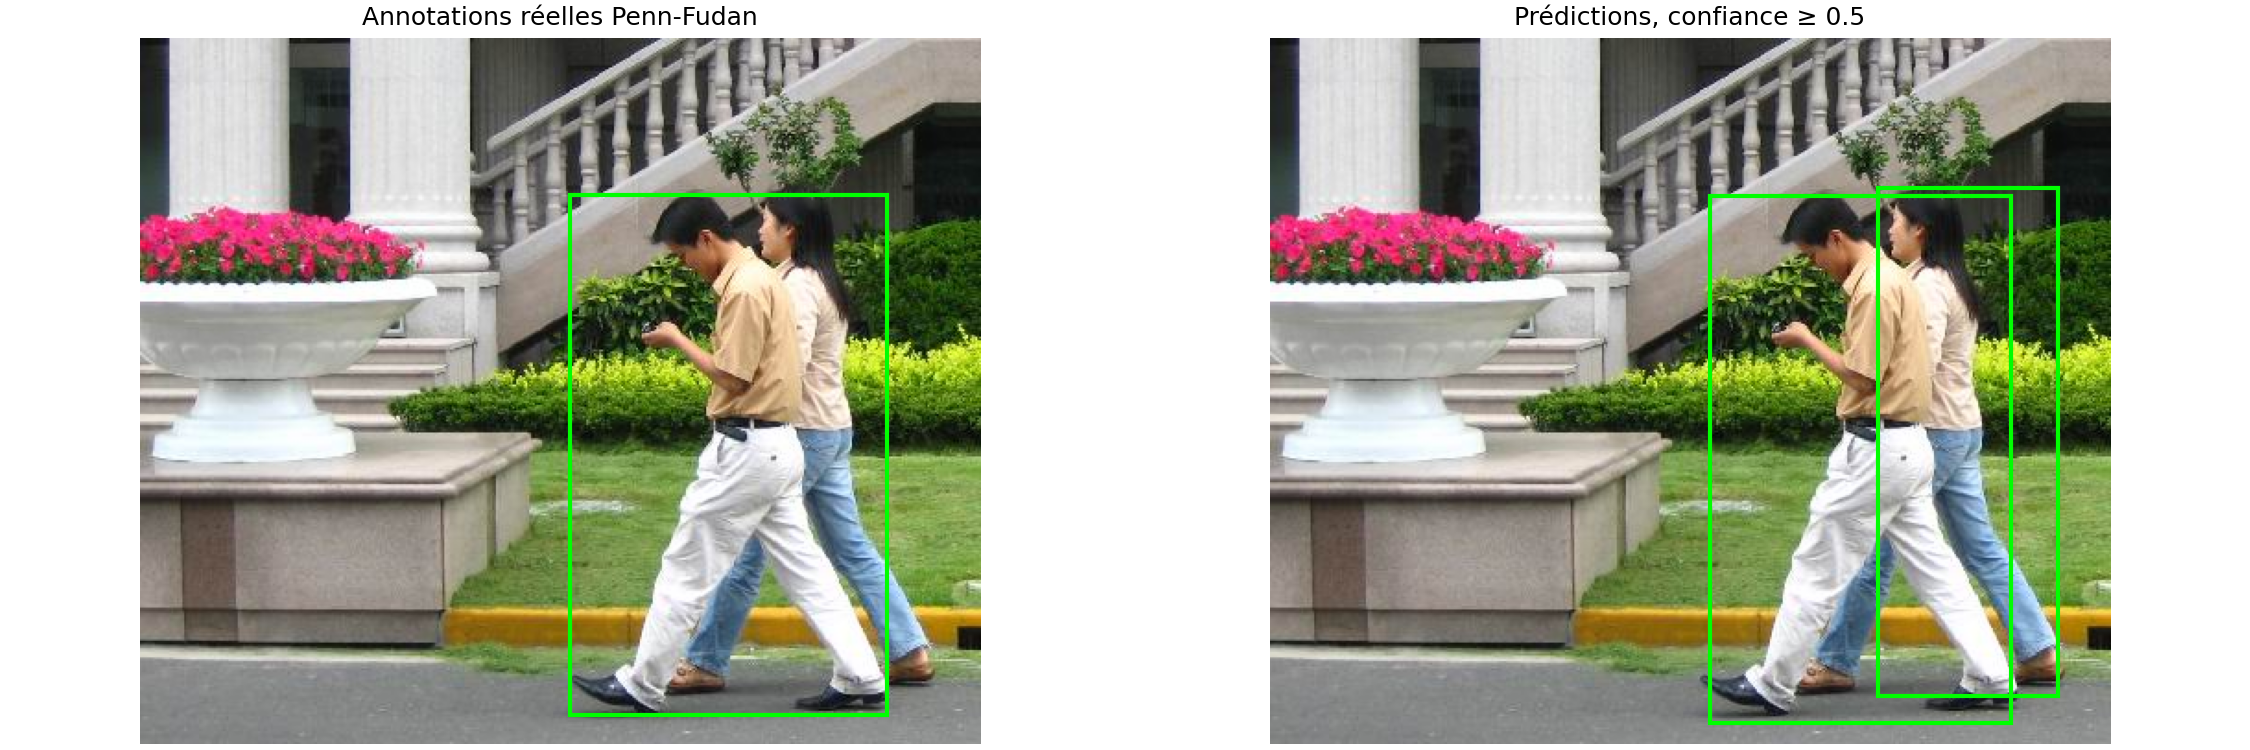

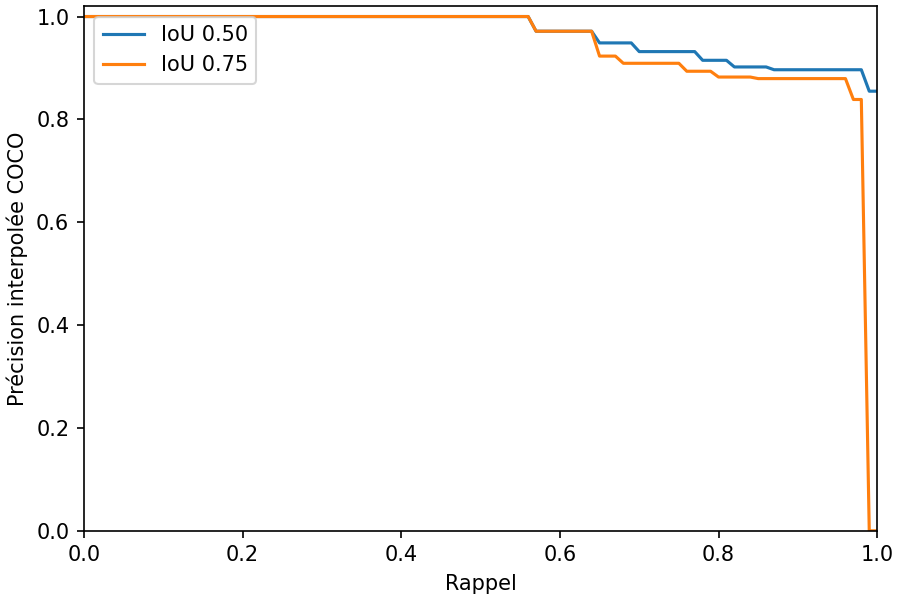

In [4]:
detection = evaluer_pietons(segmentation=False, donnees=DONNEES, sortie=SORTIE,
                            limite=LIMITE, graine=GRAINE, seuil=SEUIL, threads=2)
afficher_resume({"images": detection["n_images"], "instances": detection["n_instances"],
                 "COCO_boites": detection["coco"],
                 "precision_rappel_seuil_fixe": detection["point_fonctionnement"]})
display(Image(filename=str(SORTIE / "detection/apercu.png")))
display(Image(filename=str(SORTIE / "detection/precision_rappel.png")))

In [5]:
# Calculer une IoU à partir d'une VRAIE prédiction et des annotations de son image.
from examples.metriques import box_iou
references = json.loads((SORTIE / "detection/annotations_coco.json").read_text(encoding="utf-8"))
predictions = json.loads((SORTIE / "detection/predictions_coco.json").read_text(encoding="utf-8"))

def xyxy(boite):
    x, y, largeur, hauteur = boite
    return [x, y, x + largeur, y + hauteur]

if predictions:
    meilleure = max(predictions, key=lambda p: p["score"])
    annotations_image = [a for a in references["annotations"] if a["image_id"] == meilleure["image_id"]]
    ious = [box_iou(xyxy(meilleure["bbox"]), xyxy(a["bbox"])) for a in annotations_image]
    afficher_resume({"image_id": meilleure["image_id"], "confiance": meilleure["score"],
                     "meilleure_IoU_avec_une_annotation": max(ious, default=0.0)})
else:
    print("Aucune détection : examiner les faux négatifs, sans inventer de boîte.")

{
  "image_id": 2,
  "confiance": 0.9998488426208496,
  "meilleure_IoU_avec_une_annotation": 0.9288055718770318
}


**À interpréter :** pourquoi AP75 peut-elle être plus faible qu’AP50 ? Quel effet une double détection a-t-elle sur la précision ? L’IoU affichée dans la cellule précédente est une illustration sur une prédiction choisie par confiance, et non un score global. La précision/rappel du rapport utilise un appariement un-à-un sur toutes les images sélectionnées.

## 3 — Segmenter chaque personne, puis la classe personne

**Question concrète :** quels pixels appartiennent à quelle personne ? Et quels pixels appartiennent à au moins une personne ?

Mask R-CNN ResNet-50 FPN `COCO_V1` produit les instances. Le seuil des probabilités de masque est 0,5. La Mask AP évalue séparément ces instances avec l’API COCO. Pour la sémantique, on réunit les masques de confiance ≥ `SEUIL` et on compare à l’union des annotations.

On cumule la confusion fond/personne sur **tous les pixels** avant de calculer Pixel Accuracy, IoU, Dice et mIoU. La mIoU moyenne le fond et la personne ; les classes absentes des deux côtés sont exclues. Il s’agit d’une sémantique dérivée des instances, pas d’un U-Net distinct.

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to C:\Users\DELL\Documents\Codex\2026-11-09\referenced-chatgpt-conversation-this-is-an\work\donnees\poids\checkpoints\maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


0.1%

0.1%

0.2%

0.3%

0.4%

... (1,372 outputs left out)

segmentation : 19/20 — PennPed00083.png


segmentation : 20/20 — PennPed00085.png


creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.03s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.744
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.938
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.889
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.700
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.354
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.775
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.313
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.794
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.794
 Average Recall     (AR) @[ IoU=0.5

{
  "images": 20,
  "COCO_masques": {
    "AP_50_95": 0.7443881643324664,
    "AP_50": 0.9384564647509811,
    "AP_75": 0.8893056409657947,
    "AP_petit": 0.6999999999999998,
    "AP_moyen": 0.3544040118297544,
    "AP_grand": 0.7748673105136206,
    "AR_max1": 0.31320754716981136,
    "AR_max10": 0.7943396226415095,
    "AR_max100": 0.7943396226415095,
    "AR_petit": 0.7,
    "AR_moyen": 0.7666666666666666,
    "AR_grand": 0.8
  },
  "semantique": {
    "pixel_accuracy": 0.9544430853562478,
    "iou_fond": 0.9440234541705044,
    "iou_personne": 0.8033794993072898,
    "miou": 0.8737014767388971,
    "dice_personne": 0.8909710902401654,
    "confusion_pixels": [
      [
        3006170,
        143122
      ],
      [
        35131,
        728331
      ]
    ]
  }
}


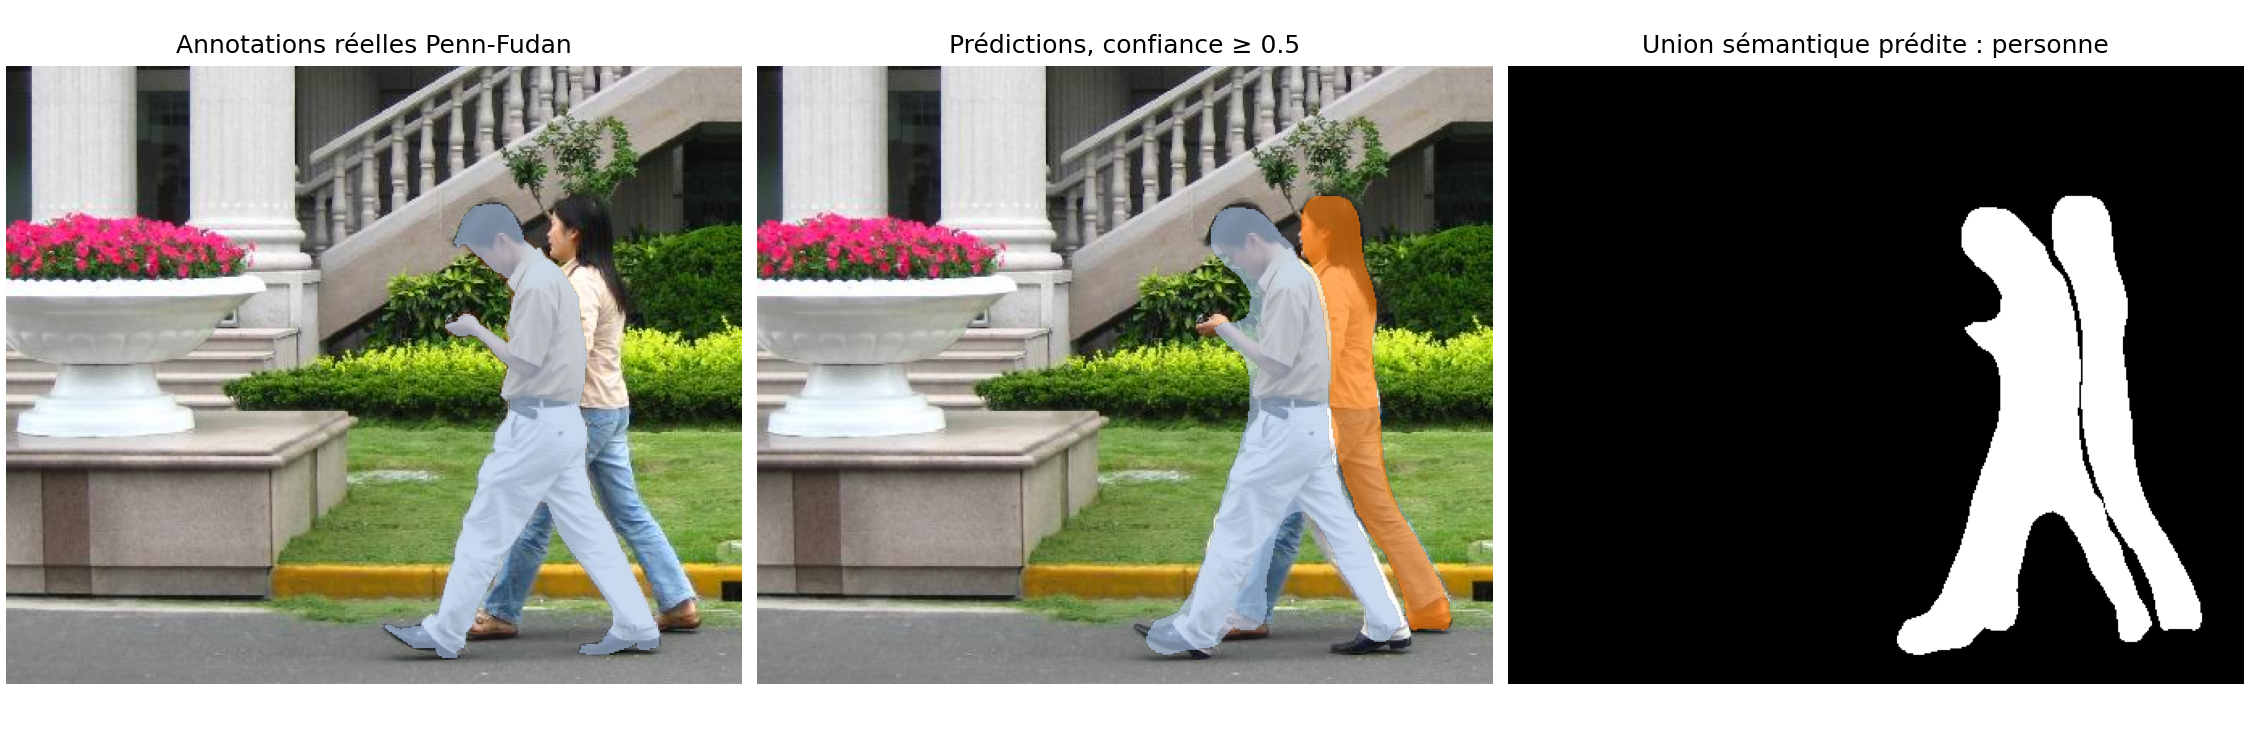

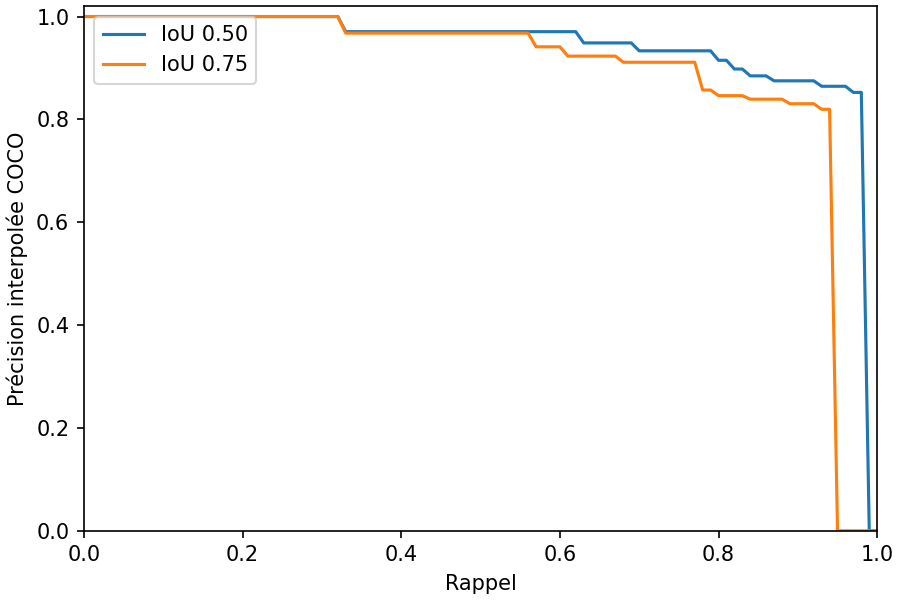

In [6]:
segmentation = evaluer_pietons(segmentation=True, donnees=DONNEES, sortie=SORTIE,
                               limite=LIMITE, graine=GRAINE, seuil=SEUIL, threads=2)
afficher_resume({"images": segmentation["n_images"],
                 "COCO_masques": segmentation["coco"],
                 "semantique": segmentation["semantique"]})
display(Image(filename=str(SORTIE / "segmentation/apercu.png")))
display(Image(filename=str(SORTIE / "segmentation/precision_rappel.png")))

In [7]:
# Vérifier que les deux modèles sont comparés sur les mêmes images.
manifestes = [json.loads((SORTIE / tache / "manifeste.json").read_text(encoding="utf-8"))
              for tache in ["detection", "segmentation"]]
assert manifestes[0] == manifestes[1]
afficher_resume({"images_evaluees": [m["image"] for m in manifestes[0]],
                 "sha256_archive": segmentation["sha256_archive"]})

{
  "images_evaluees": [
    "FudanPed00014.png",
    "FudanPed00016.png",
    "FudanPed00022.png",
    "FudanPed00033.png",
    "FudanPed00068.png",
    "PennPed00003.png",
    "PennPed00011.png",
    "PennPed00012.png",
    "PennPed00027.png",
    "PennPed00037.png",
    "PennPed00044.png",
    "PennPed00045.png",
    "PennPed00046.png",
    "PennPed00051.png",
    "PennPed00057.png",
    "PennPed00060.png",
    "PennPed00068.png",
    "PennPed00081.png",
    "PennPed00083.png",
    "PennPed00085.png"
  ],
  "sha256_archive": "9095a9613c95586f1c7f2a327d454833d16e0f5e17e5f83d35027ffd315b48e2"
}


**À interpréter :** un masque réunissant deux personnes peut avoir une bonne IoU sémantique, mais une mauvaise Mask AP. La Pixel Accuracy peut être élevée simplement parce que le fond occupe beaucoup de pixels. Lire les trois familles de mesures ensemble.

## Bilan reproductible

Les scores ci-dessous sont extraits des rapports produits par ces cellules. Ils sont sur [0, 1]. Ils ne sont ni des chiffres annoncés par les auteurs des modèles, ni un résultat sur COCO, ni un score sur tout Penn-Fudan si `LIMITE` n’est pas nul.

In [8]:
bilan = {
    "classification_accuracy_test": classification["multiclasse"]["accuracy"],
    "classification_f1_macro_test": classification["multiclasse"]["f1_macro"],
    "detection_images": detection["n_images"],
    "detection_box_AP_50_95": detection["coco"]["AP_50_95"],
    "segmentation_mask_AP_50_95": segmentation["coco"]["AP_50_95"],
    "segmentation_mIoU": segmentation["semantique"]["miou"],
    "segmentation_Dice_personne": segmentation["semantique"]["dice_personne"],
}
afficher_resume(bilan)
sauver_json(SORTIE / "bilan_notebook.json", bilan)

{
  "classification_accuracy_test": 0.9777777777777777,
  "classification_f1_macro_test": 0.9776411985388958,
  "detection_images": 20,
  "detection_box_AP_50_95": 0.8120532100874893,
  "segmentation_mask_AP_50_95": 0.7443881643324664,
  "segmentation_mIoU": 0.8737014767388971,
  "segmentation_Dice_personne": 0.8909710902401654
}


### Prolongements sans fuite du test

- Passer `LIMITE=0`, changer le dossier `SORTIE`, puis exécuter tout pour évaluer les 170 images. Ne pas présenter les scores de 20 images comme les résultats complets.
- Pour choisir un seuil ou entraîner un modèle sur Penn-Fudan, constituer d’abord des partitions apprentissage/validation/test distinctes. Ne pas optimiser le seuil sur les images qui servent à annoncer le résultat final.
- Les paramètres figés, noms de poids, empreintes, indices et versions sont conservés dans les rapports. De petites différences numériques entre plateformes restent possibles.

Sources : [UCI Digits](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits), [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), [Penn-Fudan — Wang, Shi, Song, Shen](https://www.cis.upenn.edu/~jshi/ped_html/), [TorchVision](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html), [COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py). Conditions et limites : voir README et SOURCES.